# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [9]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

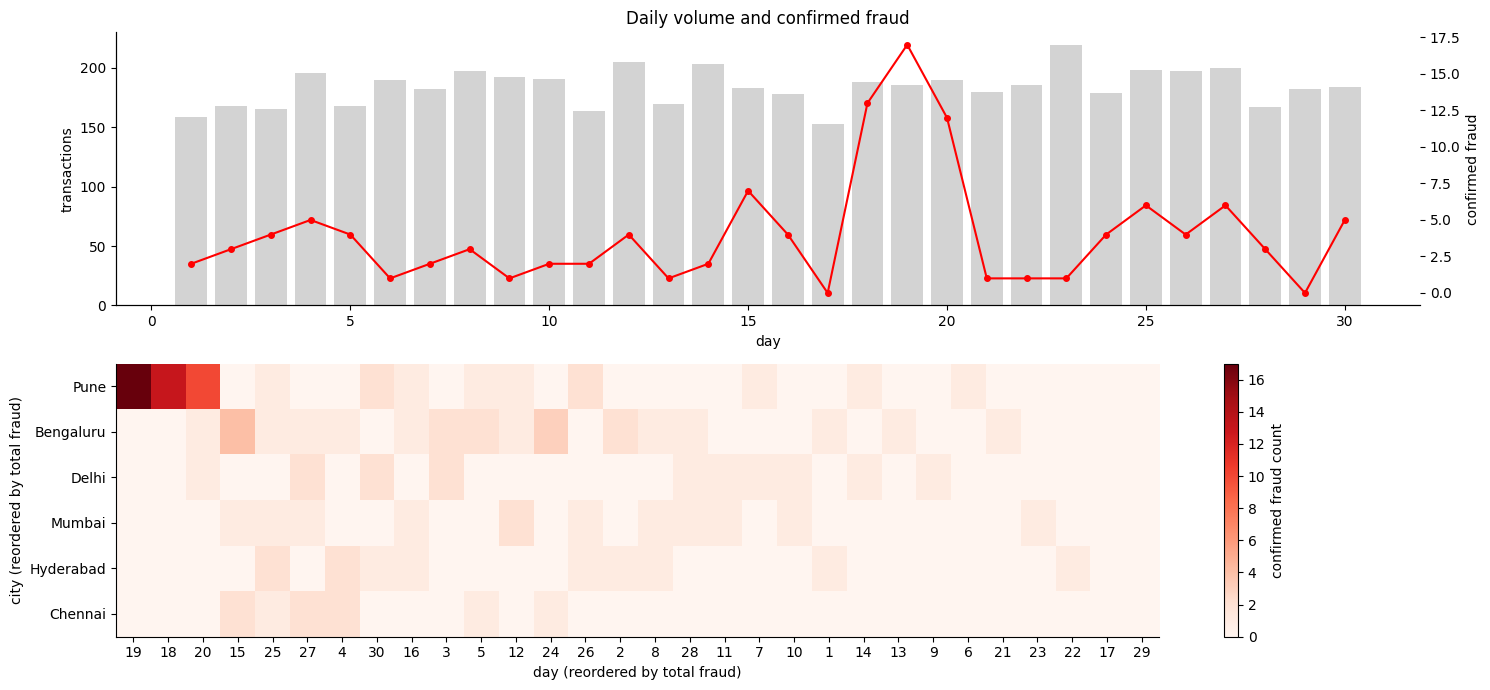

city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [10]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily_n = tx.groupby("day").size()
daily_f = tx.groupby("day").is_fraud.sum()
axes[0].bar(daily_n.index, daily_n.values, color="lightgrey", label="all transactions")
axes[0].set_xlabel("day"); axes[0].set_ylabel("transactions")
ax2 = axes[0].twinx()
ax2.plot(daily_f.index, daily_f.values, "r-o", ms=4, label="confirmed fraud")
ax2.set_ylabel("confirmed fraud")
axes[0].set_title("Daily volume and confirmed fraud")

# TODO 2
fr = tx[tx.is_fraud == 1]
m = pd.crosstab(fr.city, fr.day).reindex(columns=range(1, 31), fill_value=0)
heat = m.loc[m.sum(axis=1).sort_values(ascending=False).index,
             m.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("day (reordered by total fraud)"); axes[1].set_ylabel("city (reordered by total fraud)")
plt.colorbar(im, ax=axes[1], label="confirmed fraud count")

plt.tight_layout(); plt.show()

# TODO 3
print(heat.stack().sort_values(ascending=False).head(5))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ A list sorted by detector score shows individual suspicious transactions, but misses the bigger pattern. In this case, 40 of 120 confirmed frauds occurred in one city over three days. The reordered heatmap makes this cluster easier to spot by grouping rows and columns with higher totals together. This follows Slide 39 and Shneiderman’s “overview first” principle (Slide 30), helping investigators notice patterns before examining individual transactions.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

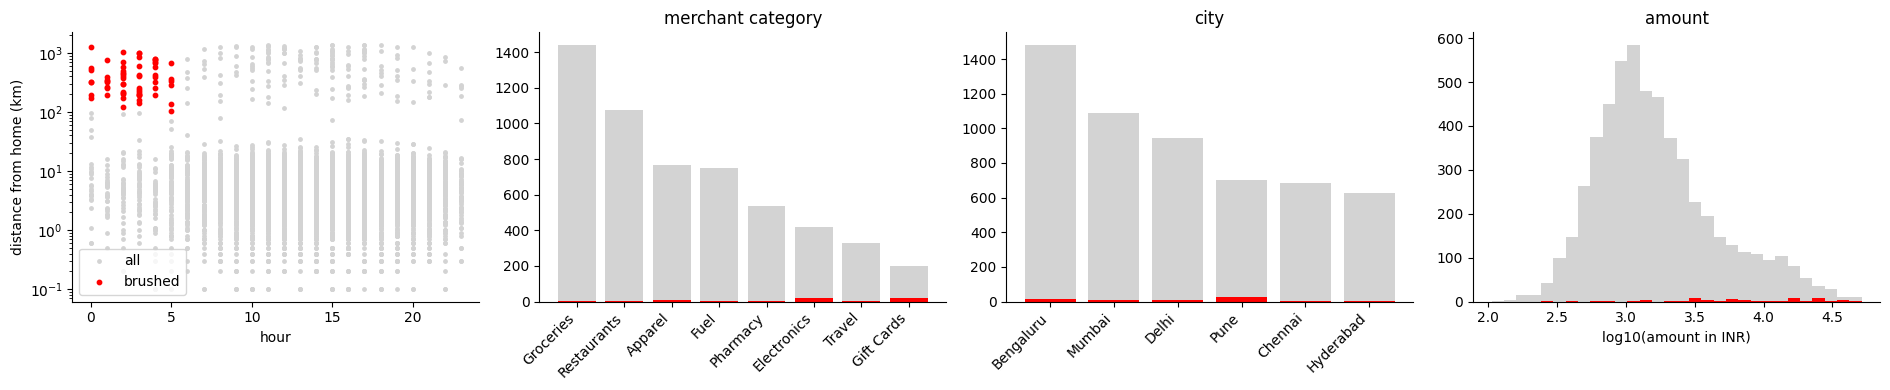

brushed: 61
fraud rate inside brush: 86.9% vs overall 2.2%
share of ALL fraud captured by brush: 44.2%


In [11]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(tx.hour, tx.distance_from_home_km, c="lightgrey", s=6, label="all")
axes[0].scatter(tx.hour[brush], tx.distance_from_home_km[brush], c="red", s=10, label="brushed")
axes[0].set_yscale("log"); axes[0].set_xlabel("hour"); axes[0].set_ylabel("distance from home (km)"); axes[0].legend()

cats = tx.merchant_category.value_counts()
x = np.arange(len(cats))
axes[1].bar(x, cats.values, color="lightgrey")
axes[1].bar(x, tx[brush].merchant_category.value_counts().reindex(cats.index, fill_value=0).values, color="red")
axes[1].set_xticks(x); axes[1].set_xticklabels(cats.index, rotation=45, ha="right"); axes[1].set_title("merchant category")

cs = tx.city.value_counts()
x = np.arange(len(cs))
axes[2].bar(x, cs.values, color="lightgrey")
axes[2].bar(x, tx[brush].city.value_counts().reindex(cs.index, fill_value=0).values, color="red")
axes[2].set_xticks(x); axes[2].set_xticklabels(cs.index, rotation=45, ha="right"); axes[2].set_title("city")

bins = np.histogram_bin_edges(np.log10(tx.amount_inr), bins=30)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color="lightgrey")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=bins, color="red")
axes[3].set_xlabel("log10(amount in INR)"); axes[3].set_title("amount")

plt.tight_layout(); plt.show()

# TODO 3
print(f"brushed: {brush.sum()}")
print(f"fraud rate inside brush: {tx[brush].is_fraud.mean():.1%} vs overall {tx.is_fraud.mean():.1%}")
print(f"share of ALL fraud captured by brush: {tx[brush].is_fraud.sum() / tx.is_fraud.sum():.1%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ The rule has a fraud rate about 40 times the baseline, but it catches only about 44% of all fraud (53 of 120 cases), so more than half of the fraud happens outside the rule. Using only this rule would miss that majority, and the investigators would still need the detector. The city view hints at where the rest is: Pune is far above its share of volume even outside the brush (27 of the unbrushed frauds are in Pune), which points to the Pune burst from Task 1.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [12]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []
for _ in range(5):
    s = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - s)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / best_s * len(big)

# TODO 3
t_50m = per_item_us * 50_000_000 / 1e6
skip_pct = max(0, 1 - 0.1 / t_50m) * 100

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 9.9 ms -> 0.0099 us/row -> max 10,123,932 rows in 0.1 s
50M rows -> 0.49 s; must skip 79.8% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ One reduce technique is sampling: filtering a random sample (say 1 to 5 million rows) so the slider reacts within the 0.1 s budget. Aggregating to bins or a precomputed summary (counts per score and amount bucket) works too. The analyst loses exactness, because the counts are estimates, and rare events such as the few fraud cases among millions may be missed or distorted in the sample.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

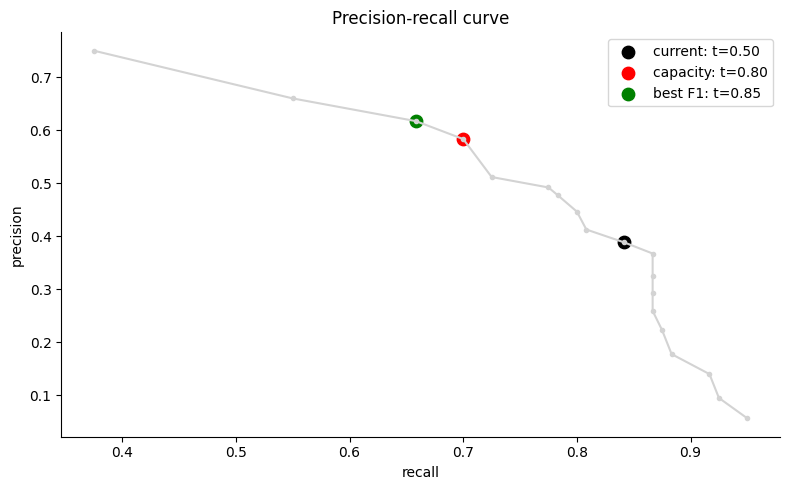

Recommend threshold 0.80: 144 alerts (within 150), precision 58%, recall 70%; current 0.5 gives 260 alerts, over capacity.


In [13]:
rows = []
# TODO 1
for t in np.arange(0.05, 1.0, 0.05):
    flag = tx.detector_score >= t
    tp = int((flag & (tx.is_fraud == 1)).sum())
    fp = int((flag & (tx.is_fraud == 0)).sum())
    fn = int((~flag & (tx.is_fraud == 1)).sum())
    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn)
    f1 = 2 * p * r / (p + r) if p + r else 0
    rows.append(dict(threshold=round(t, 2), alerts=int(flag.sum()), TP=tp, FP=fp, FN=fn,
                     precision=p, recall=r, f1=f1))

pr = pd.DataFrame(rows)

# TODO 2
capacity_choice = pr[pr.alerts <= 150].loc[lambda d: d.recall.idxmax()]
best_f1 = pr.loc[pr.f1.idxmax()]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", c="lightgrey", ms=3)
cur = pr[pr.threshold == 0.5].iloc[0]
for row, c, name in [(cur, "black", "current"), (capacity_choice, "red", "capacity"), (best_f1, "green", "best F1")]:
    ax.scatter(row.recall, row.precision, c=c, s=80, label=f"{name}: t={row.threshold:.2f}")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall curve"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommend threshold {capacity_choice.threshold:.2f}: {capacity_choice.alerts:.0f} alerts "
      f"(within 150), precision {capacity_choice.precision:.0%}, recall {capacity_choice.recall:.0%}; "
      f"current 0.5 gives {cur.alerts:.0f} alerts, over capacity.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The Head of Fraud Ops should make the final decision, not the model. The model optimises F1, but it doesn’t know the team’s workload or the cost of missing fraud. Visual analytics keeps a human in control (Slides 35–37), allowing them to compare thresholds using the precision-recall curve. Since 0.80 and 0.85 have similar F1 scores, the choice depends on whether catching 5 more frauds at 0.80 is worth handling 16 extra alerts.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [14]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig1 = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    color_discrete_map={"confirmed fraud": "red", "legitimate": "lightgrey"},
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    title="Flagged transactions (score >= 0.3)")
fig1.update_layout(dragmode="select")
fig1.show()

# TODO 2
agg = (tx.groupby(["city", "merchant_category"])
         .agg(n=("txn_id", "count"), fraud_rate=("is_fraud", "mean")).reset_index())
fig2 = px.sunburst(agg, path=["city", "merchant_category"], values="n",
                   color="fraud_rate", color_continuous_scale="Reds",
                   title="City -> merchant category (size = transactions, colour = fraud rate)")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ A tooltip shows one case at a time, so getting an overview of about 400 flagged cases means hovering over hundreds of points and mentally putting the details together. Working memory can’t hold all of that, and patterns such as a cluster in one city or time window don’t appear. The overview views from this notebook fix that: the city × day heatmap from Task 1 shows the clusters at once, and the linked views from Task 2 show how a group is distributed. Tooltips are then used for details after the overview points to where to look.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

inside window: 37.4% (40 of 107)
outside window: 1.48%   chi-square p = 1.06e-136
(a) Pune other days: 1.85%
(b) other cities, days 18-20: 0.44%


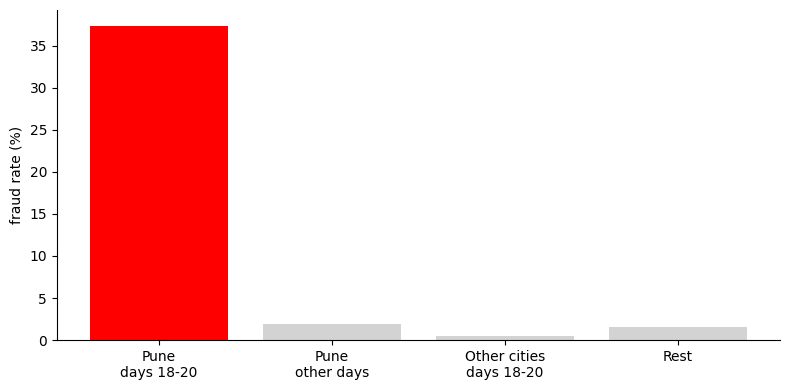

Verdict: SUPPORTED - an unusual burst confined to Pune on days 18-20 (37% fraud vs ~1.5% elsewhere, p = 1.1e-136). Escalate for investigation, but the data alone can't prove coordination.


In [15]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
chi2, p, _, _ = chi2_contingency(pd.crosstab(in_window, tx.is_fraud))
print(f"inside window: {tx[in_window].is_fraud.mean():.1%} ({tx[in_window].is_fraud.sum()} of {in_window.sum()})")
print(f"outside window: {tx[~in_window].is_fraud.mean():.2%}   chi-square p = {p:.2e}")

# TODO 3
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = (tx.city != "Pune") & ~tx.day.between(18, 20)
print(f"(a) Pune other days: {tx[same_city_other_days].is_fraud.mean():.2%}")
print(f"(b) other cities, days 18-20: {tx[other_cities_same_days].is_fraud.mean():.2%}")

# TODO 4
groups = {"Pune\ndays 18-20": in_window, "Pune\nother days": same_city_other_days,
          "Other cities\ndays 18-20": other_cities_same_days, "Rest": rest}
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(groups), [tx[m].is_fraud.mean() * 100 for m in groups.values()],
       color=["red", "lightgrey", "lightgrey", "lightgrey"])
ax.set_ylabel("fraud rate (%)")
plt.tight_layout(); plt.show()

# TODO 5
print("Verdict: SUPPORTED - an unusual burst confined to Pune on days 18-20 "
      f"({tx[in_window].is_fraud.mean():.0%} fraud vs ~{tx[~in_window].is_fraud.mean():.1%} elsewhere, p = {p:.1e}). "
      "Escalate for investigation, but the data alone can't prove coordination.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ Search (b), other cities on the same days, was the one that could have killed the idea. If those cities had also shown a jump on days 18 to 20, the cause would be something time-based and system-wide, such as a detector fault, a data issue or a payment-network event, not anything specific to Pune. Search (a) matters too: a high rate in Pune on other days would have pointed to a permanently risky city. Both came out low, so the burst is specific to Pune in that window. Note that “ring” is a stronger claim than this shows.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_ Last month, PayKart had 120 frauds out of 5,520 transactions (2.2%). Of these, 40 occurred in Pune over three days, with a 37% fraud rate compared to 1.5% elsewhere. This suggests a localised attack rather than general drift. I’d raise the threshold from 0.5 to 0.80 to stay within the 150-alert limit, giving 144 alerts, 58% precision, and 70% recall. Since 0.85 has a similar F1 score, Fraud Ops should make the final decision based on the cost of missed fraud versus extra reviews. I’d build a city-by-day heatmap linked to a scatter plot for details on demand, following “overview first, then details.” To meet the 0.1-second response target, I’d sample or pre-aggregate the 50-million-row history. Finally, I’d use investigators’ confirmed labels to retrain and recalibrate the detector for next month (Slide 51).